In [2]:
import pandas as pd
import numpy as np
import keras
from sklearn.metrics import r2_score,root_mean_squared_error,matthews_corrcoef,mean_squared_error
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
from sklearn import svm
from sanfis import SANFIS
from sanfis.datagenerators import sanfis_generator
import torch
from sklearn.model_selection import GridSearchCV
from keras_tuner import RandomSearch,GridSearch
from keras_tuner.engine.hyperparameters import HyperParameters
import tensorflow.keras.backend as K
import tensorflow as tf
from keras.models import Sequential
from tensorflow.keras.metrics import Metric
import pickle
import pywt
import seaborn as sns


In [ ]:

@keras.saving.register_keras_serializable()
class NashSutcliffeEfficiency(Metric):
    def __init__(self, name='nse', **kwargs):
        super(NashSutcliffeEfficiency, self).__init__(name=name, **kwargs)
        self.numerator = self.add_weight(name='numerator', initializer='zeros')
        self.denominator = self.add_weight(name='denominator', initializer='zeros')
        self.count = self.add_weight(name='count', initializer='zeros')

    def update_state(self, y_true, y_pred, sample_weight=None):
        numerator = tf.reduce_sum(tf.square(y_true - y_pred))
        denominator = tf.reduce_sum(tf.square(y_true - tf.reduce_mean(y_true)))
        self.numerator.assign_add(numerator)
        self.denominator.assign_add(denominator)
        self.count.assign_add(1)

    def result(self):
        nse = 1 - (self.numerator / (self.denominator+1e-9))
        return nse

    def reset_states(self):
        self.numerator.assign(0)
        self.denominator.assign(0)
        self.count.assign(0)
def get_season(month):
    if month in [12, 1, 2]:
        return "Winter"
    elif month in [3, 4, 5]:
        return "Spring"
    elif month in [6, 7, 8]:
        return "Summer"
    else:
        return "Autumn"


tf.keras.utils.get_custom_objects()['NashSutcliffeEfficiency'] = NashSutcliffeEfficiency

station='sf' #Specify the station name by choosing the appropriate folder sheet name. In this case, it is 'sf' standing for San Francisco. you can choose among [sf,mi,ph,ch] 
ffnn_model_ssp5 = keras.models.load_model(f".\Sample Date\historical Inputs\{station}\ffnn_{station}.keras", custom_objects={'NashSutcliffeEfficiency': NashSutcliffeEfficiency})



with open(f".\Sample Date\historical Inputs\{station}\anfis\anfis_{station}.pickle", 'rb') as f:
    fis_ssp5 = pickle.load(f)



with open(f".\Sample Date\historical Inputs\{station}\svr\svr_model_{station}.pickle", 'rb') as f:
    svr_model_ssp5 = pickle.load(f)

ensemble_model_ssp5 = keras.models.load_model(f".\Sample Date\historical Inputs\{station}\ensemble\ensemble_{station}.keras", custom_objects={'NashSutcliffeEfficiency': NashSutcliffeEfficiency})



ffnn_model_ssp2 = keras.models.load_model(f".\Sample Date\historical Inputs\{station}\ffnn_{station}.keras", custom_objects={'NashSutcliffeEfficiency': NashSutcliffeEfficiency})


with open(f".\Sample Date\historical Inputs\{station}\anfis\anfis_{station}.pickle", 'rb') as f:
    fis_ssp2 = pickle.load(f)


with open(f".\Sample Date\historical Inputs\{station}\svr\svr_model_{station}.pickle", 'rb') as f:
    svr_model_ssp2 = pickle.load(f)

ensemble_model_ssp2 = keras.models.load_model(f".\Sample Date\historical Inputs\{station}\ensemble\ensemble_{station}.keras", custom_objects={'NashSutcliffeEfficiency': NashSutcliffeEfficiency})



In [ ]:
sf_ssp245 = pd.read_excel(f".\Sample Date\ssp inputs\{station}\ssp_245_{station}_inputs.xlsx").set_index(pd.date_range(start='2015-01-01', end='2100-12-01', freq='MS'))
sf_ssp585 = pd.read_excel(f".\Sample Date\ssp inputs\{station}\ssp_585_{station}_inputs.xlsx").set_index(pd.date_range(start='2015-01-01', end='2100-12-01', freq='MS'))

# Assuming sf_ssp is a combination of sf_ssp245 and sf_ssp585 for the period up to 2024-12-01
sf_ssp245 = sf_ssp245[sf_ssp245.index <= '2024-12-01']
sf_ssp585 = sf_ssp585[sf_ssp585.index <= '2024-12-01']

sf_ssp245['monthsin'] = np.sin(2 * np.pi * sf_ssp245.index.month / 12)
sf_ssp245['monthcos'] = np.cos(2 * np.pi * sf_ssp245.index.month / 12)
sf_ssp585['monthsin'] = np.sin(2 * np.pi * sf_ssp585.index.month / 12)
sf_ssp585['monthcos'] = np.cos(2 * np.pi * sf_ssp585.index.month / 12)

observations_raw = pd.read_excel(f".\Sample Date\observation\{station}\{station}_obs_2015_2024.xlsx").set_index(pd.date_range(start='2015-01-01', end='2024-12-01', freq='MS')).drop(columns='date') 
ssp245_scaler, ssp585_scaler, obs_scaler = StandardScaler(), StandardScaler(), StandardScaler()
time = observations_raw.index

In [5]:
ssp2_revalidation_input = sf_ssp245.reset_index(drop=True)

ssp2_revalidation_fis_input = torch.tensor(ssp245_scaler.fit_transform(sf_ssp245[['r7i1p1f1,gr1',	'r7i1p1f1,gr2',	'r7i1p1f1,gr3',	'r7i1p1f1,gr4','monthsin','monthcos']].values), dtype=torch.float32)

ssp2_revalidation_input = ssp245_scaler.fit_transform(ssp2_revalidation_input)

observations_scaled = obs_scaler.fit_transform(observations_raw)



4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
R2 Score FFNN SSP2: 0.25588685538936196
R2 Score SVR SSP2: 0.2991029765314065
R2 Score ANFIS SSP2: 0.3273912002265149
R2 Score Ensemble SSP2: 0.2369454516858147


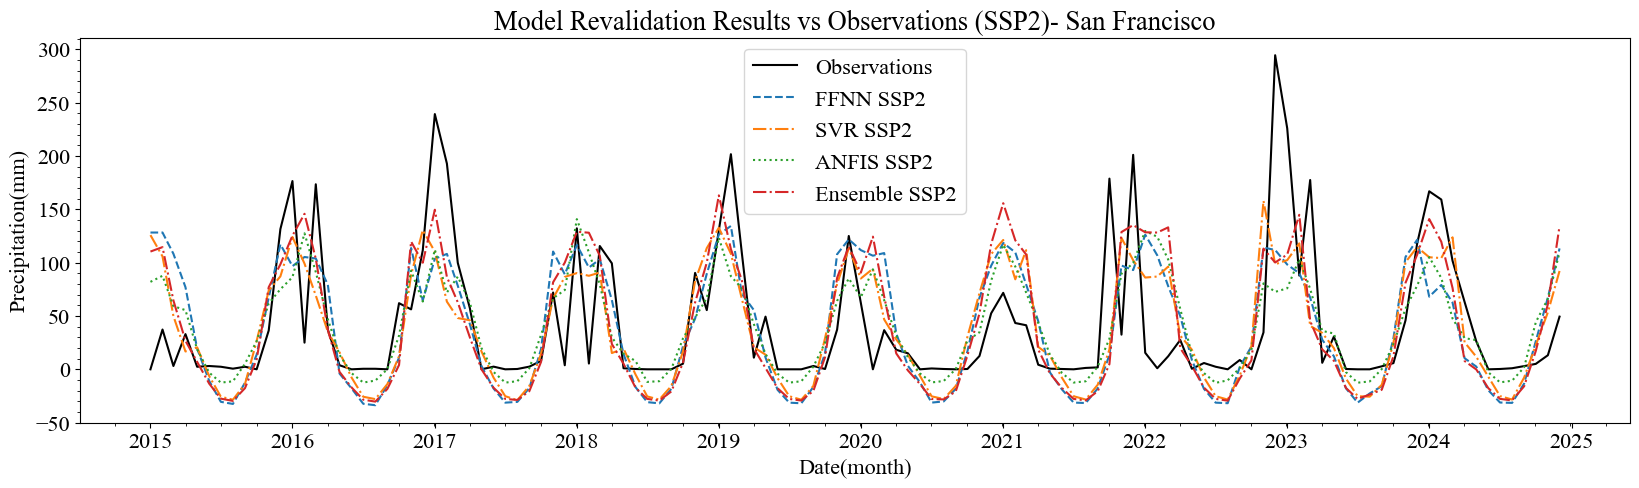

In [6]:
predictions = pd.DataFrame(columns=['FFNN_SSP2', 'ANFIS_SSP5', 'SVR_SSP2'])
predictions['FFNN_SSP2'] = obs_scaler.inverse_transform(ffnn_model_ssp2.predict(ssp2_revalidation_input).reshape(-1, 1)).flatten()

predictions['SVR_SSP2'] = obs_scaler.inverse_transform(svr_model_ssp2.predict(ssp2_revalidation_input).reshape(-1, 1)).flatten()

predictions['ANFIS_SSP2'] = obs_scaler.inverse_transform(fis_ssp2.predict(ssp2_revalidation_fis_input))

ensemble_input_scaler = StandardScaler()
ensemble_input_ssp2 = ensemble_input_scaler.fit_transform(predictions[['FFNN_SSP2', 'SVR_SSP2', 'ANFIS_SSP2']])

revalidation_ensemble_ssp2 = obs_scaler.inverse_transform(ensemble_model_ssp2.predict(ensemble_input_ssp2))
r2_ffnn_ssp2 = r2_score(observations_raw['PRCP'], predictions['FFNN_SSP2'])
r2_svr_ssp2 = r2_score(observations_raw['PRCP'], predictions['SVR_SSP2'])
r2_anfis_ssp2 = r2_score(observations_raw['PRCP'], predictions['ANFIS_SSP2'])
r2_ensemble_ssp2 = r2_score(observations_raw['PRCP'], revalidation_ensemble_ssp2)
print(f'R2 Score FFNN SSP2: {r2_ffnn_ssp2}')
print(f'R2 Score SVR SSP2: {r2_svr_ssp2}')
print(f'R2 Score ANFIS SSP2: {r2_anfis_ssp2}')
print(f'R2 Score Ensemble SSP2: {r2_ensemble_ssp2}')


plt.rcParams["font.family"] = "Times New Roman"
plt.rcParams["font.size"] = 16

plt.figure(figsize=(20, 5))
plt.plot(observations_raw, label='Observations', color='black')

plt.plot(observations_raw.index, predictions['FFNN_SSP2'], label='FFNN SSP2', linestyle='--')
plt.plot(observations_raw.index, predictions['SVR_SSP2'], label='SVR SSP2', linestyle='-.')
plt.plot(observations_raw.index, predictions['ANFIS_SSP2'], label='ANFIS SSP2', linestyle=':')
plt.plot(observations_raw.index, revalidation_ensemble_ssp2, label='Ensemble SSP2', linestyle='-.')

plt.xlabel('Date(month)')
plt.ylabel('Precipitation(mm)')
plt.minorticks_on()
plt.title('Model Revalidation Results vs Observations (SSP2)- San Francisco')
plt.legend()
plt.show()

In [7]:
ssp5_revalidation_input = sf_ssp585
ssp5_revalidation_fis_input = torch.tensor(ssp585_scaler.fit_transform(sf_ssp585[['r1i1p1f1,gr1',  'r1i1p1f1,gr2', 'r1i1p1f1,gr3',  'r1i1p1f1,gr4','monthsin','monthcos']].values), dtype=torch.float32)
ssp5_revalidation_input = ssp585_scaler.fit_transform(ssp5_revalidation_input)

1/4 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/stepWARNING:tensorflow:6 out of the last 12 calls to <function TensorFlowTrainer.make_predict_function.<locals>.one_step_on_data_distributed at 0x000002C71F3A6840> triggered tf.function retracing. Tracing is expensive and the excessive number of tracings could be due to (1) creating @tf.function repeatedly in a loop, (2) passing tensors with different shapes, (3) passing Python objects instead of tensors. For (1), please define your @tf.function outside of the loop. For (2), @tf.function has reduce_retracing=True option that can avoid unnecessary retracing. For (3), please refer to https://www.tensorflow.org/guide/function#controlling_retracing and https://www.tensorflow.org/api_docs/python/tf/function for  more details.
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
R2 Score FFNN SSP5: 0.325134406136643
R2 Score SVR SSP5: 0.3078528187114109
R2 Score ANFIS SSP5: 0.274798343312152
R2 Score Ensemble SSP5: 0.23712026564522315


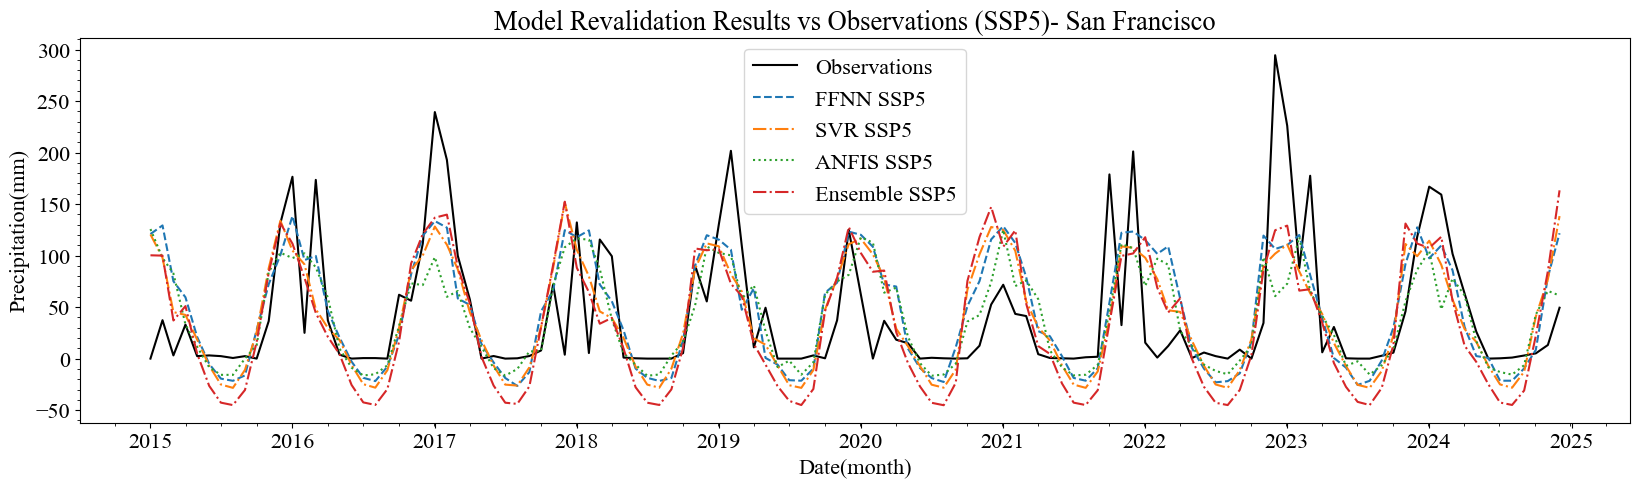

In [8]:
predictions = pd.DataFrame(columns=['FFNN_SSP5', 'ANFIS_SSP5', 'SVR_SSP5'])
predictions['FFNN_SSP5'] = obs_scaler.inverse_transform(ffnn_model_ssp5.predict(ssp5_revalidation_input).reshape(-1, 1)).flatten()
predictions['SVR_SSP5'] = obs_scaler.inverse_transform(svr_model_ssp5.predict(ssp5_revalidation_input).reshape(-1, 1)).flatten()
predictions['ANFIS_SSP5'] = obs_scaler.inverse_transform(fis_ssp5.predict(ssp5_revalidation_fis_input))
ensemble_input_ssp5 = ensemble_input_scaler.fit_transform(predictions[['FFNN_SSP5', 'SVR_SSP5', 'ANFIS_SSP5']])
revalidation_ensemble_ssp5 = obs_scaler.inverse_transform(ensemble_model_ssp5.predict(ensemble_input_ssp5))
r2_ffnn_ssp5 = r2_score(observations_raw['PRCP'], predictions['FFNN_SSP5'])
r2_svr_ssp5 = r2_score(observations_raw['PRCP'], predictions['SVR_SSP5'])
r2_anfis_ssp5 = r2_score(observations_raw['PRCP'], predictions['ANFIS_SSP5'])
r2_ensemble_ssp5 = r2_score(observations_raw['PRCP'], revalidation_ensemble_ssp5)


print(f'R2 Score FFNN SSP5: {r2_ffnn_ssp5}')
print(f'R2 Score SVR SSP5: {r2_svr_ssp5}')
print(f'R2 Score ANFIS SSP5: {r2_anfis_ssp5}')
print(f'R2 Score Ensemble SSP5: {r2_ensemble_ssp5}')

plt.rcParams["font.family"] = "Times New Roman"
plt.rcParams["font.size"] = 16

plt.figure(figsize=(20, 5))
plt.plot(observations_raw, label='Observations', color='black')

plt.plot(observations_raw.index, predictions['FFNN_SSP5'], label='FFNN SSP5', linestyle='--')
plt.plot(observations_raw.index, predictions['SVR_SSP5'], label='SVR SSP5', linestyle='-.')
plt.plot(observations_raw.index, predictions['ANFIS_SSP5'], label='ANFIS SSP5', linestyle=':')
plt.plot(observations_raw.index, revalidation_ensemble_ssp5, label='Ensemble SSP5', linestyle='-.')

plt.xlabel('Date(month)')
plt.ylabel('Precipitation(mm)')
plt.minorticks_on()
plt.title('Model Revalidation Results vs Observations (SSP5)- San Francisco')
plt.legend()
plt.show()


4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
R2 Score FFNN SSP2: 0.3095352246715327
R2 Score SVR SSP2: 0.33584070529483023
R2 Score ANFIS SSP2: 0.3338668489221437
R2 Score Ensemble SSP2: 0.266302975982072


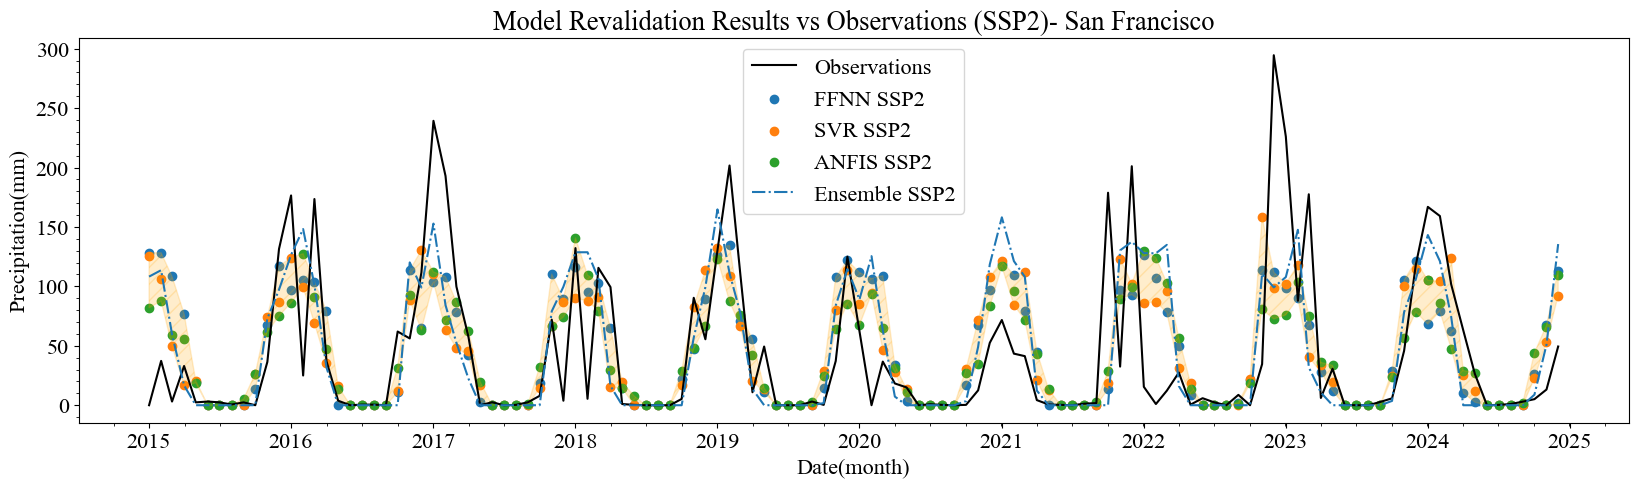

In [9]:
predictions = pd.DataFrame(columns=['FFNN_SSP2', 'ANFIS_SSP2', 'SVR_SSP2'])
predictions['FFNN_SSP2'] = obs_scaler.inverse_transform(ffnn_model_ssp2.predict(ssp2_revalidation_input).reshape(-1, 1)).flatten()
predictions['SVR_SSP2'] = obs_scaler.inverse_transform(svr_model_ssp2.predict(ssp2_revalidation_input).reshape(-1, 1)).flatten()
predictions['ANFIS_SSP2'] = obs_scaler.inverse_transform(fis_ssp2.predict(ssp2_revalidation_fis_input))

# Convert negative values to 0
predictions = predictions.clip(lower=0)

ensemble_input_scaler = StandardScaler()
ensemble_input_ssp2 = ensemble_input_scaler.fit_transform(predictions[['FFNN_SSP2', 'SVR_SSP2', 'ANFIS_SSP2']])

revalidation_ensemble_ssp2 = obs_scaler.inverse_transform(ensemble_model_ssp2.predict(ensemble_input_ssp2))
revalidation_ensemble_ssp2 = np.clip(revalidation_ensemble_ssp2, a_min=0, a_max=None)
r2_ffnn_ssp2 = r2_score(observations_raw['PRCP'], predictions['FFNN_SSP2'])
r2_svr_ssp2 = r2_score(observations_raw['PRCP'], predictions['SVR_SSP2'])
r2_anfis_ssp2 = r2_score(observations_raw['PRCP'], predictions['ANFIS_SSP2'])
r2_ensemble_ssp2 = r2_score(observations_raw['PRCP'], revalidation_ensemble_ssp2)
print(f'R2 Score FFNN SSP2: {r2_ffnn_ssp2}')
print(f'R2 Score SVR SSP2: {r2_svr_ssp2}')
print(f'R2 Score ANFIS SSP2: {r2_anfis_ssp2}')
print(f'R2 Score Ensemble SSP2: {r2_ensemble_ssp2}')
min_pred = predictions.min(axis=1)  # Lower bound
max_pred = predictions.max(axis=1)  # Upper bound

plt.rcParams["font.family"] = "Times New Roman"
plt.rcParams["font.size"] = 16

plt.figure(figsize=(20, 5))
plt.plot(observations_raw, label='Observations', color='black')

plt.scatter(observations_raw.index, pd.to_numeric(predictions['FFNN_SSP2'], errors='coerce'), label='FFNN SSP2')
plt.scatter(observations_raw.index, pd.to_numeric(predictions['SVR_SSP2'], errors='coerce'), label='SVR SSP2')
plt.scatter(observations_raw.index, pd.to_numeric(predictions['ANFIS_SSP2'], errors='coerce'), label='ANFIS SSP2')
plt.fill_between(observations_raw.index, pd.to_numeric(min_pred, errors='coerce'), pd.to_numeric(max_pred, errors='coerce'), alpha=0.2, color='orange', capstyle='round', hatch='//')
plt.plot(observations_raw.index, revalidation_ensemble_ssp2, label='Ensemble SSP2', linestyle='-.')

plt.xlabel('Date(month)')
plt.ylabel('Precipitation(mm)')
plt.minorticks_on()
plt.title('Model Revalidation Results vs Observations (SSP2)- San Francisco')
plt.legend()
plt.show()

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
R2 Score FFNN SSP5: 0.3498878416231762
R2 Score SVR SSP5: 0.34312607126737993
R2 Score ANFIS SSP5: 0.28626190363337667
R2 Score Ensemble SSP5: 0.32876505869178263


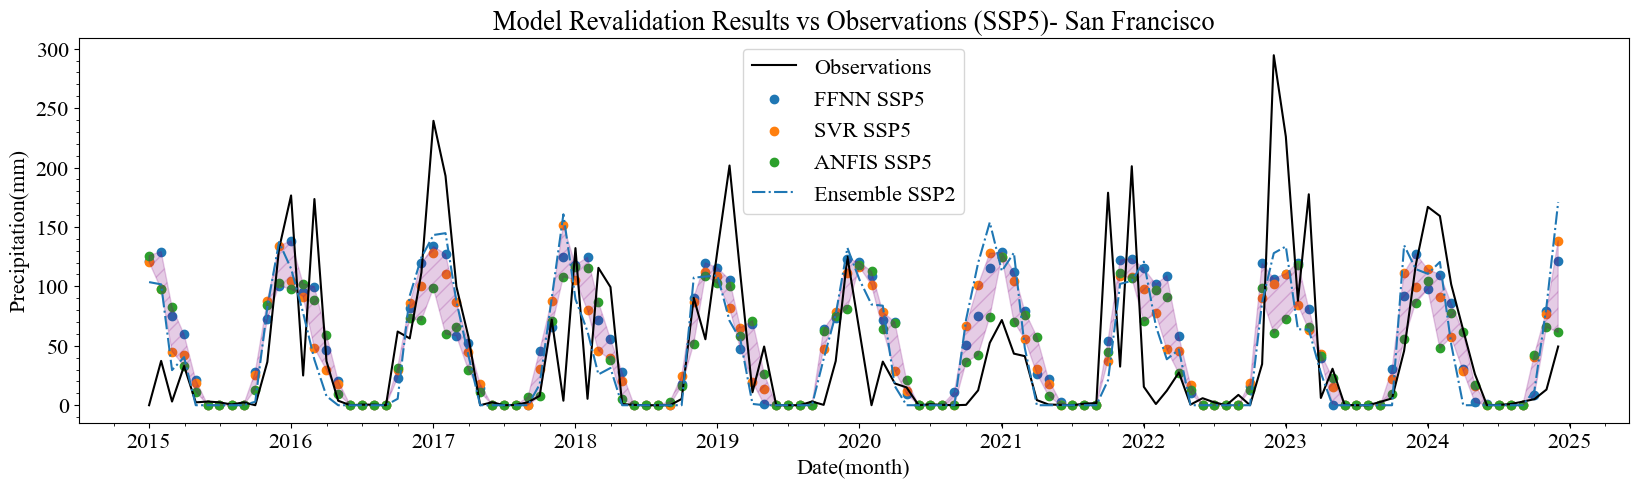

In [10]:
predictions = pd.DataFrame(columns=['FFNN_SSP5', 'ANFIS_SSP5', 'SVR_SSP5'])
predictions['FFNN_SSP5'] = obs_scaler.inverse_transform(ffnn_model_ssp5.predict(ssp5_revalidation_input).reshape(-1, 1)).flatten()
predictions['SVR_SSP5'] = obs_scaler.inverse_transform(svr_model_ssp5.predict(ssp5_revalidation_input).reshape(-1, 1)).flatten()
predictions['ANFIS_SSP5'] = obs_scaler.inverse_transform(fis_ssp5.predict(ssp5_revalidation_fis_input))

# Convert negative values to 0
predictions = predictions.clip(lower=0)

ensemble_input_scaler = StandardScaler()
ensemble_input_ssp5 = ensemble_input_scaler.fit_transform(predictions[['FFNN_SSP5', 'SVR_SSP5', 'ANFIS_SSP5']])

revalidation_ensemble_ssp5 = obs_scaler.inverse_transform(ensemble_model_ssp5.predict(ensemble_input_ssp5))
revalidation_ensemble_ssp5 = np.clip(revalidation_ensemble_ssp5, a_min=0, a_max=None)
r2_ffnn_ssp5 = r2_score(observations_raw['PRCP'], predictions['FFNN_SSP5'])
r2_svr_ssp5 = r2_score(observations_raw['PRCP'], predictions['SVR_SSP5'])
r2_anfis_ssp5 = r2_score(observations_raw['PRCP'], predictions['ANFIS_SSP5'])
r2_ensemble_ssp5 = r2_score(observations_raw['PRCP'], revalidation_ensemble_ssp5)
print(f'R2 Score FFNN SSP5: {r2_ffnn_ssp5}')
print(f'R2 Score SVR SSP5: {r2_svr_ssp5}')
print(f'R2 Score ANFIS SSP5: {r2_anfis_ssp5}')
print(f'R2 Score Ensemble SSP5: {r2_ensemble_ssp5}')
# Binarize the continuous data
obs_binary = (observations_raw['PRCP'] > 0).astype(int)
pred_ffnn_binary = (predictions['FFNN_SSP5'] > 0).astype(int)
pred_svr_binary = (predictions['SVR_SSP5'] > 0).astype(int)
pred_anfis_binary = (predictions['ANFIS_SSP5'] > 0).astype(int)
pred_ensemble_binary = (revalidation_ensemble_ssp5 > 0).astype(int)

min_pred = predictions.min(axis=1)  # Lower bound
max_pred = predictions.max(axis=1)  # Upper bound

plt.rcParams["font.family"] = "Times New Roman"
plt.rcParams["font.size"] = 16

plt.figure(figsize=(20, 5))
plt.plot(observations_raw, label='Observations', color='black')

plt.scatter(observations_raw.index, pd.to_numeric(predictions['FFNN_SSP5'], errors='coerce'), label='FFNN SSP5')
plt.scatter(observations_raw.index, pd.to_numeric(predictions['SVR_SSP5'], errors='coerce'), label='SVR SSP5')
plt.scatter(observations_raw.index, pd.to_numeric(predictions['ANFIS_SSP5'], errors='coerce'), label='ANFIS SSP5')
plt.fill_between(observations_raw.index, pd.to_numeric(min_pred, errors='coerce'), pd.to_numeric(max_pred, errors='coerce'), alpha=0.2, color='purple', capstyle='round', hatch='//')
plt.plot(observations_raw.index, revalidation_ensemble_ssp5, label='Ensemble SSP2', linestyle='-.')

plt.xlabel('Date(month)')
plt.ylabel('Precipitation(mm)')
plt.minorticks_on()
plt.title('Model Revalidation Results vs Observations (SSP5)- San Francisco')
plt.legend()
plt.show()

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 697us/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 930us/step


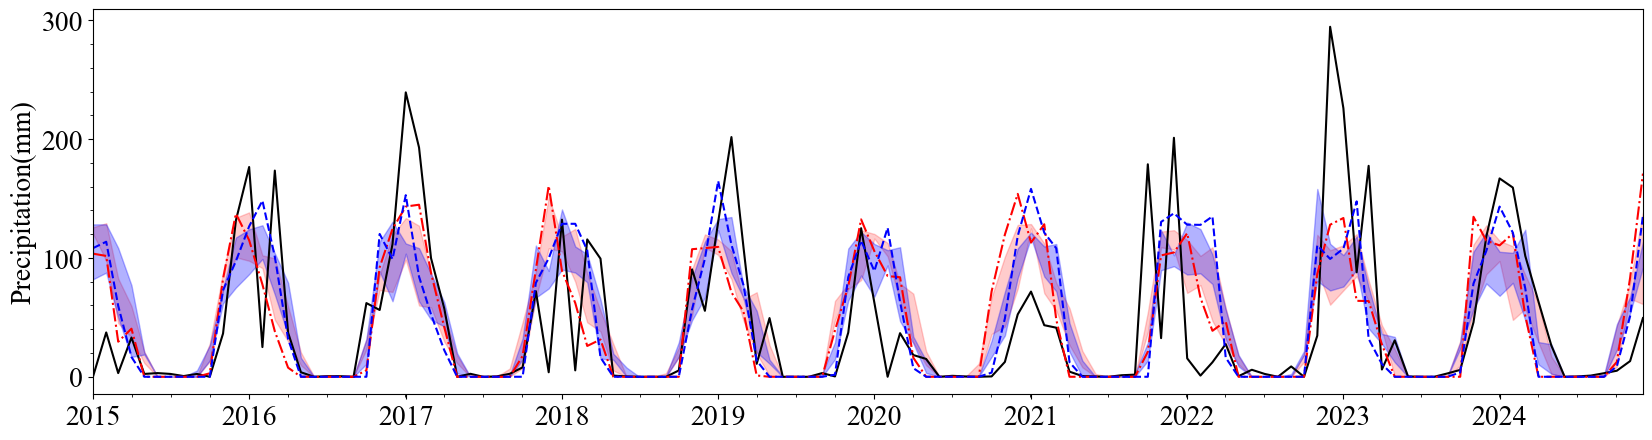

In [11]:
predictions = pd.DataFrame(columns=['FFNN_SSP5', 'ANFIS_SSP5', 'SVR_SSP5','FFNN_SSP2', 'ANFIS_SSP2', 'SVR_SSP2'])
predictions['FFNN_SSP5'] = obs_scaler.inverse_transform(ffnn_model_ssp5.predict(ssp5_revalidation_input).reshape(-1, 1)).flatten()
predictions['SVR_SSP5'] = obs_scaler.inverse_transform(svr_model_ssp5.predict(ssp5_revalidation_input).reshape(-1, 1)).flatten()
predictions['ANFIS_SSP5'] = obs_scaler.inverse_transform(fis_ssp5.predict(ssp5_revalidation_fis_input))
predictions['FFNN_SSP2'] = obs_scaler.inverse_transform(ffnn_model_ssp2.predict(ssp2_revalidation_input).reshape(-1, 1)).flatten()
predictions['SVR_SSP2'] = obs_scaler.inverse_transform(svr_model_ssp2.predict(ssp2_revalidation_input).reshape(-1, 1)).flatten()
predictions['ANFIS_SSP2'] = obs_scaler.inverse_transform(fis_ssp2.predict(ssp2_revalidation_fis_input))

# Convert negative values to 0
predictions = predictions.clip(lower=0)

ensemble_input_scaler = StandardScaler()
ensemble_input_ssp5 = ensemble_input_scaler.fit_transform(predictions[['FFNN_SSP5', 'SVR_SSP5', 'ANFIS_SSP5']])
ensemble_input_ssp2 = ensemble_input_scaler.fit_transform(predictions[['FFNN_SSP2', 'SVR_SSP2', 'ANFIS_SSP2']])

revalidation_ensemble_ssp5 = obs_scaler.inverse_transform(ensemble_model_ssp5.predict(ensemble_input_ssp5))
revalidation_ensemble_ssp5 = np.clip(revalidation_ensemble_ssp5, a_min=0, a_max=None)
revalidation_ensemble_ssp2 = obs_scaler.inverse_transform(ensemble_model_ssp2.predict(ensemble_input_ssp2))
revalidation_ensemble_ssp2 = np.clip(revalidation_ensemble_ssp2, a_min=0, a_max=None)
r2_ffnn_ssp5 = r2_score(observations_raw['PRCP'], predictions['FFNN_SSP5'])
r2_svr_ssp5 = r2_score(observations_raw['PRCP'], predictions['SVR_SSP5'])
r2_anfis_ssp5 = r2_score(observations_raw['PRCP'], predictions['ANFIS_SSP5'])
r2_ensemble_ssp5 = r2_score(observations_raw['PRCP'], revalidation_ensemble_ssp5)

min_pred_ssp2 = predictions[['FFNN_SSP2', 'ANFIS_SSP2', 'SVR_SSP2']].min(axis=1)  # Lower bound for SSP2
max_pred_ssp2 = predictions[['FFNN_SSP2', 'ANFIS_SSP2', 'SVR_SSP2']].max(axis=1)  # Upper bound for SSP2

min_pred_ssp5 = predictions[['FFNN_SSP5', 'ANFIS_SSP5', 'SVR_SSP5']].min(axis=1)  # Lower bound for SSP5
max_pred_ssp5 = predictions[['FFNN_SSP5', 'ANFIS_SSP5', 'SVR_SSP5']].max(axis=1)  # Upper bound for SSP5

plt.rcParams["font.family"] = "Times New Roman"
plt.rcParams["font.size"] = 20

plt.figure(figsize=(20, 5))
plt.plot(observations_raw, label='Observations', color='black')

#plt.scatter(observations_raw.index, pd.to_numeric(predictions['FFNN_SSP5'], errors='coerce'), label='FFNN SSP5', marker='.', color='mediumpurple', alpha=0.5)
#plt.scatter(observations_raw.index, pd.to_numeric(predictions['SVR_SSP5'], errors='coerce'), label='SVR SSP5', marker='.', color='rebeccapurple', alpha=0.5)
#plt.scatter(observations_raw.index, pd.to_numeric(predictions['ANFIS_SSP5'], errors='coerce'), label='ANFIS SSP5', marker='.', color='indigo', alpha=0.5)
plt.fill_between(observations_raw.index, pd.to_numeric(min_pred_ssp5, errors='coerce'), pd.to_numeric(max_pred_ssp5, errors='coerce'), alpha=0.2, color='red', capstyle='round', label='Shallow Models Prediction Range (SSP5)')
plt.plot(observations_raw.index, revalidation_ensemble_ssp5, label='Ensemble SSP5', linestyle='-.', color='red')

# Adding SSP2 plots
#plt.scatter(observations_raw.index, pd.to_numeric(predictions['FFNN_SSP2'], errors='coerce'), label='FFNN SSP2', marker='.', color='orange', alpha=0.5)
#plt.scatter(observations_raw.index, pd.to_numeric(predictions['SVR_SSP2'], errors='coerce'), label='SVR SSP2', marker='.', color='darkorange', alpha=0.5)
#plt.scatter(observations_raw.index, pd.to_numeric(predictions['ANFIS_SSP2'], errors='coerce'), label='ANFIS SSP2', marker='.', color='orangered', alpha=0.5)
plt.fill_between(observations_raw.index, pd.to_numeric(min_pred_ssp2, errors='coerce'), pd.to_numeric(max_pred_ssp2, errors='coerce'), alpha=0.3, color='blue', capstyle='round', label='Shallow Models Prediction Range (SSP2)')
plt.plot(observations_raw.index, revalidation_ensemble_ssp2, label='Ensemble SSP2', linestyle='--', color='blue',alpha=1)

#plt.xlabel('Date(month)')
plt.ylabel('Precipitation(mm)')
plt.minorticks_on()
#plt.title('Model Revalidation Results vs Observations (SSP5 and SSP2)- San Francisco')
#plt.legend(ncol=9, fontsize=20, loc='upper center', bbox_to_anchor=(0.5, 1.5))
plt.xlim(pd.Timestamp('2015-01-01'), pd.Timestamp('2024-12-01'))
plt.show()

In [ ]:
projection_ssp245 = pd.read_excel(f".\Sample Date\ssp inputs\{station}\ssp_245_{station}_inputs.xlsx").set_index(pd.date_range(start='2015-01-01', end='2100-12-01', freq='MS'))
projection_ssp585 = pd.read_excel(f".\Sample Date\ssp inputs\{station}\ssp_585_{station}_inputs.xlsx").set_index(pd.date_range(start='2015-01-01', end='2100-12-01', freq='MS'))
projection_ssp245['monthsin'] = np.sin(2 * np.pi * projection_ssp245.index.month / 12)
projection_ssp245['monthcos'] = np.cos(2 * np.pi * projection_ssp245.index.month / 12)
projection_ssp585['monthsin'] = np.sin(2 * np.pi * projection_ssp585.index.month / 12)
projection_ssp585['monthcos'] = np.cos(2 * np.pi * projection_ssp585.index.month / 12)
projection_ssp245_scaler, projection_ssp585_scaler = StandardScaler(), StandardScaler()

projection_ssp245_fis_input= torch.tensor(projection_ssp245_scaler.fit_transform(projection_ssp245[['r7i1p1f1,gr1', 'r7i1p1f1,gr2', 'r7i1p1f1,gr3', 'r7i1p1f1,gr4','monthsin','monthcos']].values), dtype=torch.float32)
projection_ssp245_input= projection_ssp245_scaler.fit_transform(projection_ssp245)
projection_ssp585_fis_input= torch.tensor(projection_ssp585_scaler.fit_transform(projection_ssp585[['r1i1p1f1,gr1',  'r1i1p1f1,gr2',  'r1i1p1f1,gr3', 'r1i1p1f1,gr4','monthsin','monthcos']].values), dtype=torch.float32)
projection_ssp585_input= projection_ssp585_scaler.fit_transform(projection_ssp585)


33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 823us/step
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 708us/step


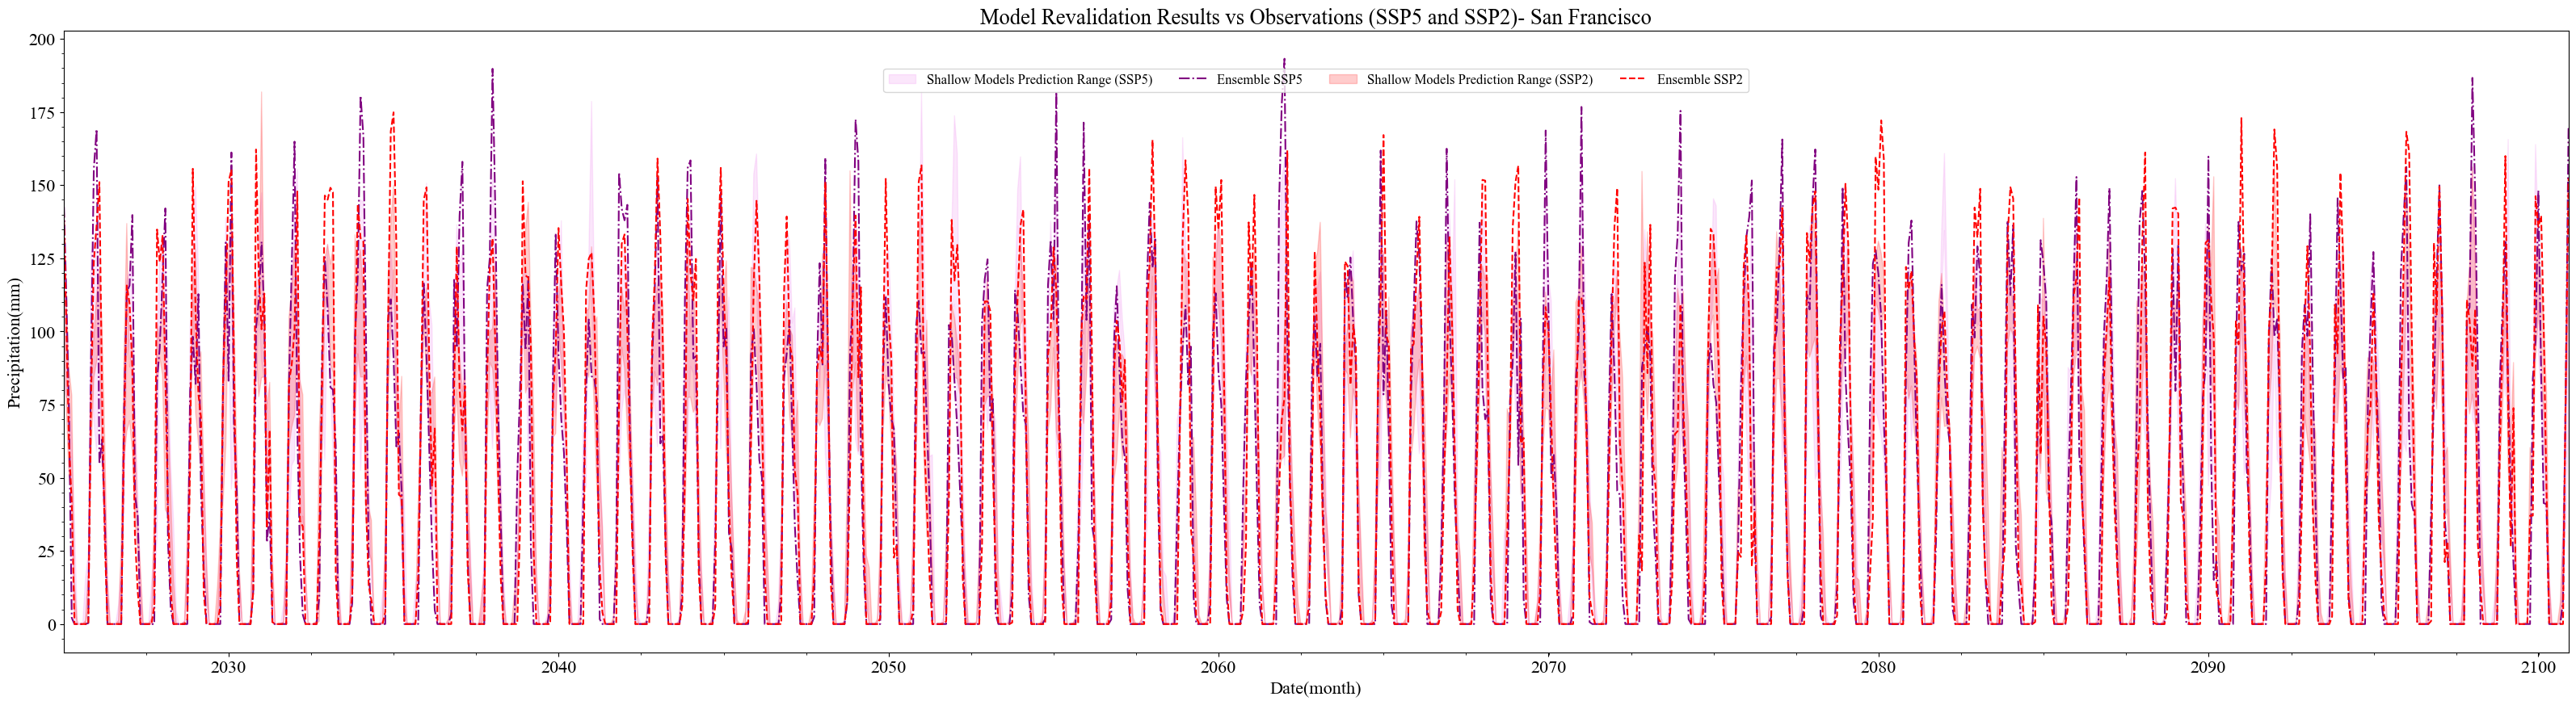

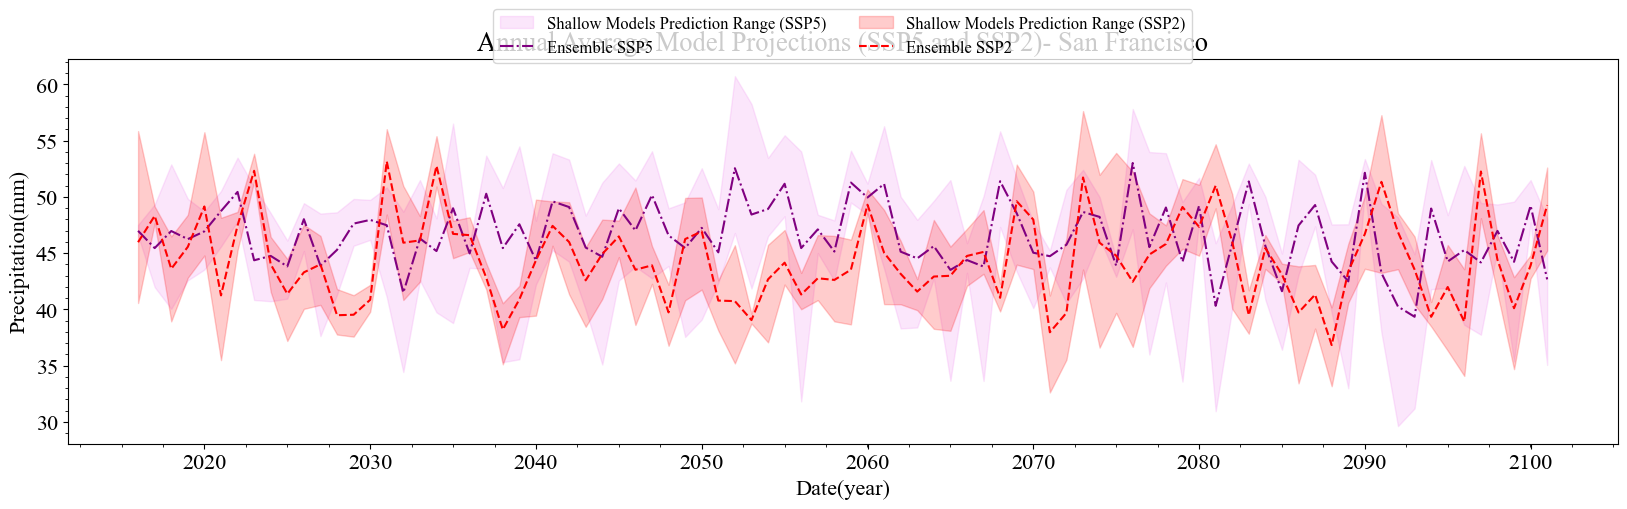

In [13]:
projections=pd.DataFrame(columns=['FFNN_SSP5', 'ANFIS_SSP5', 'SVR_SSP5','FFNN_SSP2', 'ANFIS_SSP2', 'SVR_SSP2'], index=projection_ssp245.index)
projections['FFNN_SSP5'] = obs_scaler.inverse_transform(ffnn_model_ssp5.predict(projection_ssp585_input).reshape(-1, 1)).flatten()
projections['SVR_SSP5'] = obs_scaler.inverse_transform(svr_model_ssp5.predict(projection_ssp585_input).reshape(-1, 1)).flatten()
projections['ANFIS_SSP5'] = obs_scaler.inverse_transform(fis_ssp5.predict(projection_ssp585_fis_input))
projections['FFNN_SSP2'] = obs_scaler.inverse_transform(ffnn_model_ssp2.predict(projection_ssp245_input).reshape(-1, 1)).flatten()
projections['SVR_SSP2'] = obs_scaler.inverse_transform(svr_model_ssp2.predict(projection_ssp245_input).reshape(-1, 1)).flatten()
projections['ANFIS_SSP2'] = obs_scaler.inverse_transform(fis_ssp2.predict(projection_ssp245_fis_input))

projections = projections.clip(lower=0)

ensemble_input_scaler = StandardScaler()
ensemble_input_ssp2 = ensemble_input_scaler.fit_transform(projections[['FFNN_SSP2', 'SVR_SSP2', 'ANFIS_SSP2']])
ensemble_input_ssp5= ensemble_input_scaler.fit_transform(projections[['FFNN_SSP5', 'SVR_SSP5', 'ANFIS_SSP5']])

revalidation_ensemble_ssp2 = obs_scaler.inverse_transform(ensemble_model_ssp2.predict(ensemble_input_ssp2).reshape(-1, 1)).flatten()
revalidation_ensemble_ssp2 = np.clip(revalidation_ensemble_ssp2, a_min=0, a_max=None)
revalidation_ensemble_ssp5 = obs_scaler.inverse_transform(ensemble_model_ssp5.predict(ensemble_input_ssp5).reshape(-1, 1)).flatten()
revalidation_ensemble_ssp5 = np.clip(revalidation_ensemble_ssp5, a_min=0, a_max=None)
projections['Ensemble_SSP2']= revalidation_ensemble_ssp2
projections['Ensemble_SSP5']= revalidation_ensemble_ssp5

min_pred_ssp2 = projections[['FFNN_SSP2', 'ANFIS_SSP2', 'SVR_SSP2']].min(axis=1)  # Lower bound for SSP2
max_pred_ssp2 = projections[['FFNN_SSP2', 'ANFIS_SSP2', 'SVR_SSP2']].max(axis=1)  # Upper bound for SSP2

min_pred_ssp5 = projections[['FFNN_SSP5', 'ANFIS_SSP5', 'SVR_SSP5']].min(axis=1)  # Lower bound for SSP5
max_pred_ssp5 = projections[['FFNN_SSP5', 'ANFIS_SSP5', 'SVR_SSP5']].max(axis=1)  # Upper bound for SSP5



plt.rcParams["font.family"] = "Times New Roman"
plt.rcParams["font.size"] = 16

plt.figure(figsize=(40, 10))



plt.fill_between(projection_ssp245.index, pd.to_numeric(min_pred_ssp5, errors='coerce'), pd.to_numeric(max_pred_ssp5, errors='coerce'), alpha=0.2, color='violet', capstyle='round', label='Shallow Models Prediction Range (SSP5)')
plt.plot(projection_ssp245.index, revalidation_ensemble_ssp5, label='Ensemble SSP5', linestyle='-.', color='purple')


plt.fill_between(projection_ssp585.index, pd.to_numeric(min_pred_ssp2, errors='coerce'), pd.to_numeric(max_pred_ssp2, errors='coerce'), alpha=0.2, color='red', capstyle='round', label='Shallow Models Prediction Range (SSP2)')
plt.plot(projection_ssp585.index, revalidation_ensemble_ssp2, label='Ensemble SSP2', linestyle='--', color='red')

plt.xlabel('Date(month)')
plt.ylabel('Precipitation(mm)')
plt.minorticks_on()
plt.title('Model Revalidation Results vs Observations (SSP5 and SSP2)- San Francisco')
plt.legend(ncol=9, fontsize=12, loc='upper center', bbox_to_anchor=(0.5, 0.95))
plt.xlim(pd.Timestamp('2025-01-01'), pd.Timestamp('2100-12-01'))
plt.show()

# Convert monthly data to annual average
projections_annual = projections.resample('A').mean()

# Plot the annual average projections
plt.figure(figsize=(20, 5))

plt.fill_between(projections_annual.index, pd.to_numeric(projections_annual[['FFNN_SSP5', 'ANFIS_SSP5', 'SVR_SSP5']].min(axis=1), errors='coerce'), pd.to_numeric(projections_annual[['FFNN_SSP5', 'ANFIS_SSP5', 'SVR_SSP5']].max(axis=1), errors='coerce'), alpha=0.2, color='violet', capstyle='round', label='Shallow Models Prediction Range (SSP5)')
plt.plot(projections_annual.index, projections_annual[['FFNN_SSP5', 'ANFIS_SSP5', 'SVR_SSP5']].mean(axis=1), label='Ensemble SSP5', linestyle='-.', color='purple')

plt.fill_between(projections_annual.index, pd.to_numeric(projections_annual[['FFNN_SSP2', 'ANFIS_SSP2', 'SVR_SSP2']].min(axis=1), errors='coerce'), pd.to_numeric(projections_annual[['FFNN_SSP2', 'ANFIS_SSP2', 'SVR_SSP2']].max(axis=1), errors='coerce'), alpha=0.2, color='red', capstyle='round', label='Shallow Models Prediction Range (SSP2)')
plt.plot(projections_annual.index, projections_annual[['FFNN_SSP2', 'ANFIS_SSP2', 'SVR_SSP2']].mean(axis=1), label='Ensemble SSP2', linestyle='--', color='red')

plt.xlabel('Date(year)')
plt.ylabel('Precipitation(mm)')
plt.minorticks_on()
plt.title('Annual Average Model Projections (SSP5 and SSP2)- San Francisco')
plt.legend(ncol=2, fontsize=12, loc='upper center', bbox_to_anchor=(0.5, 1.15))
plt.show()


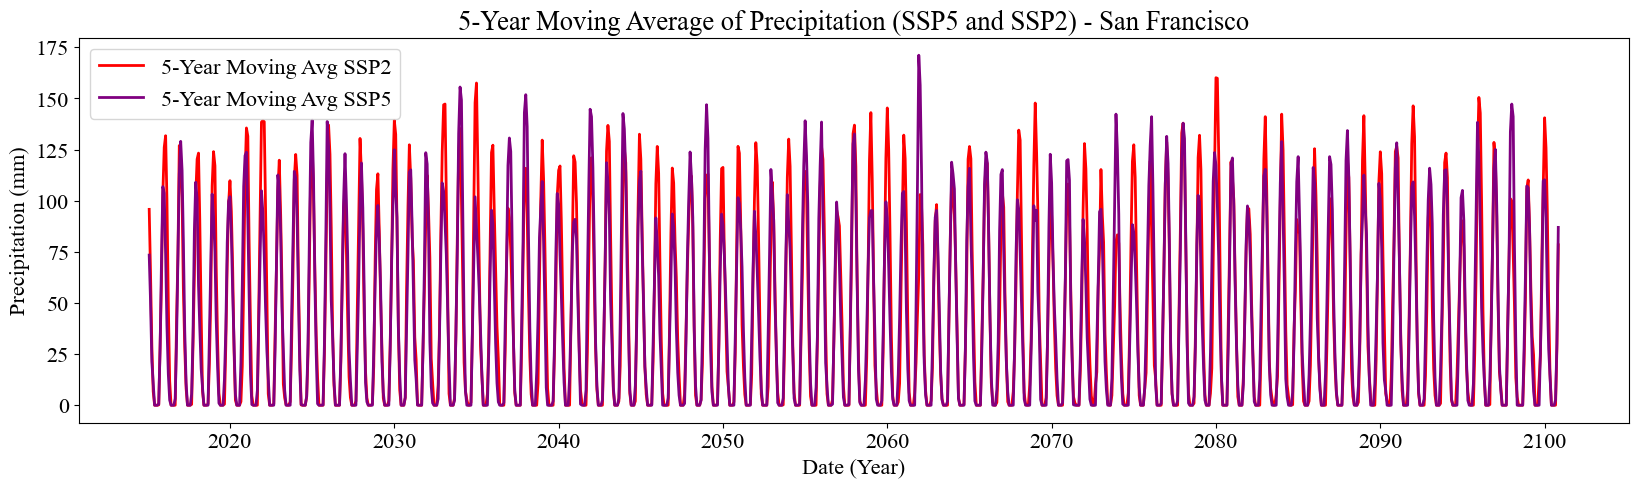

In [14]:
projections['rolling_avg_ssp2'] = projections['Ensemble_SSP2'].rolling(3, center=True).mean()
projections['rolling_avg_ssp5'] = projections['Ensemble_SSP5'].rolling(3, center=True).mean()

plt.figure(figsize=(20, 5))
plt.plot(projections.index, projections['rolling_avg_ssp2'], label='5-Year Moving Avg SSP2', linestyle='-', color='red', linewidth=2)
plt.plot(projections.index, projections['rolling_avg_ssp5'], label='5-Year Moving Avg SSP5', linestyle='-', color='purple', linewidth=2)

plt.xlabel('Date (Year)')
plt.ylabel('Precipitation (mm)')
plt.title('5-Year Moving Average of Precipitation (SSP5 and SSP2) - San Francisco')
plt.legend()
plt.show()


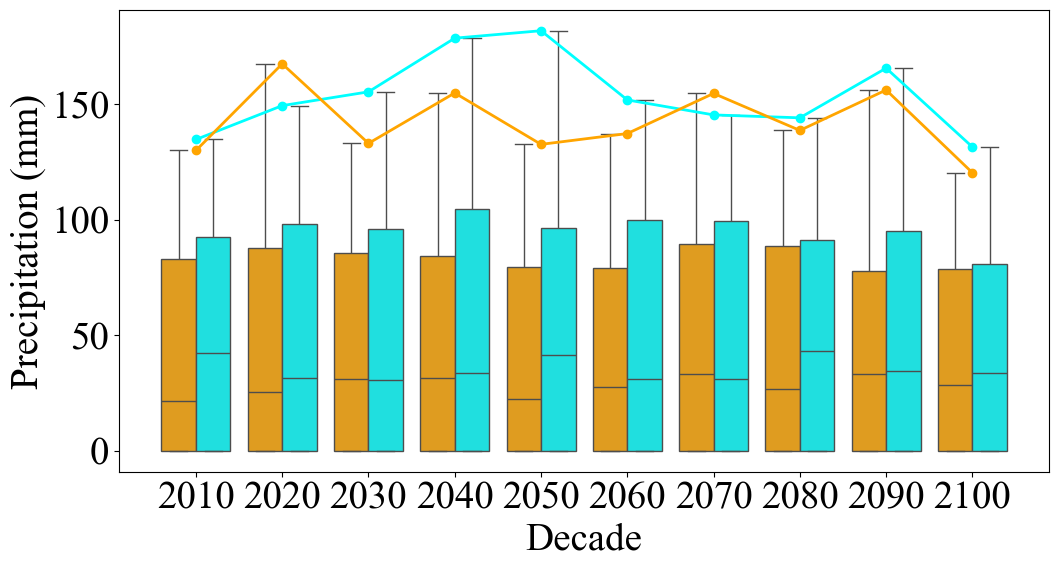

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Assuming 'projections' already has a DateTime index and the 'Ensemble_SSP2' and 'FFNN_SSP5' columns
projections['decade'] = (projections.index.year // 10) * 10

# Melt your DataFrame so that each row corresponds to one scenario's precipitation value
melted_df = pd.melt(
    projections.reset_index(), 
    id_vars=['index','decade'], 
    value_vars=['SVR_SSP2', 'FFNN_SSP5'],
    var_name='scenario', 
    value_name='precipitation'
)

# Define the order of decades (as numbers)
order = sorted(melted_df['decade'].unique())
# Create a mapping from decade to its position (0, 1, 2, ...)
decade_to_pos = {dec: pos for pos, dec in enumerate(order)}

plt.figure(figsize=(12, 6))

# Create the boxplot with the specified order
ax = sns.boxplot(
    data=melted_df,
    x='decade', 
    y='precipitation',
    hue='scenario',
    palette={'FFNN_SSP5': 'cyan', 'SVR_SSP2': 'orange'},
    showfliers=True,
    whis=100,
    order=order,
    legend=False
)

plt.xlabel('Decade')
plt.ylabel('Precipitation (mm)')
#plt.title('Decadal Precipitation Variability - Ensemble under SSP5 & SSP2')

# Compute the mean precipitation per decade for each scenario
mean_df = melted_df.groupby(['scenario', 'decade'], as_index=False)['precipitation'].max()

# Define colors matching your palette
colors = {'FFNN_SSP5': 'cyan', 'SVR_SSP2': 'orange'}

# Overlay a line connecting the means for each scenario using the mapped positions
for scenario, group in mean_df.groupby('scenario'):
    group = group.sort_values('decade')
    # Map each decade value to its x-axis position from the boxplot
    x_positions = [decade_to_pos[dec] for dec in group['decade']]
    plt.plot(x_positions, group['precipitation'], 
             marker='o', linestyle='-', linewidth=2, 
             color=colors[scenario], 
             label=f'Max {scenario}')

# Since the x-axis is categorical, update the tick positions and labels accordingly
plt.xticks(ticks=range(len(order)), labels=order)
plt.rcParams['font.size']=28
# Combine legends and adjust (avoid duplicate legend entries)
handles, labels = ax.get_legend_handles_labels()
# Remove duplicates by using a dictionary
unique = dict(zip(labels, handles))
#plt.legend(unique.values(), unique.keys(),  loc='center left', bbox_to_anchor=(1, 0.5), ncol=4)

plt.show()


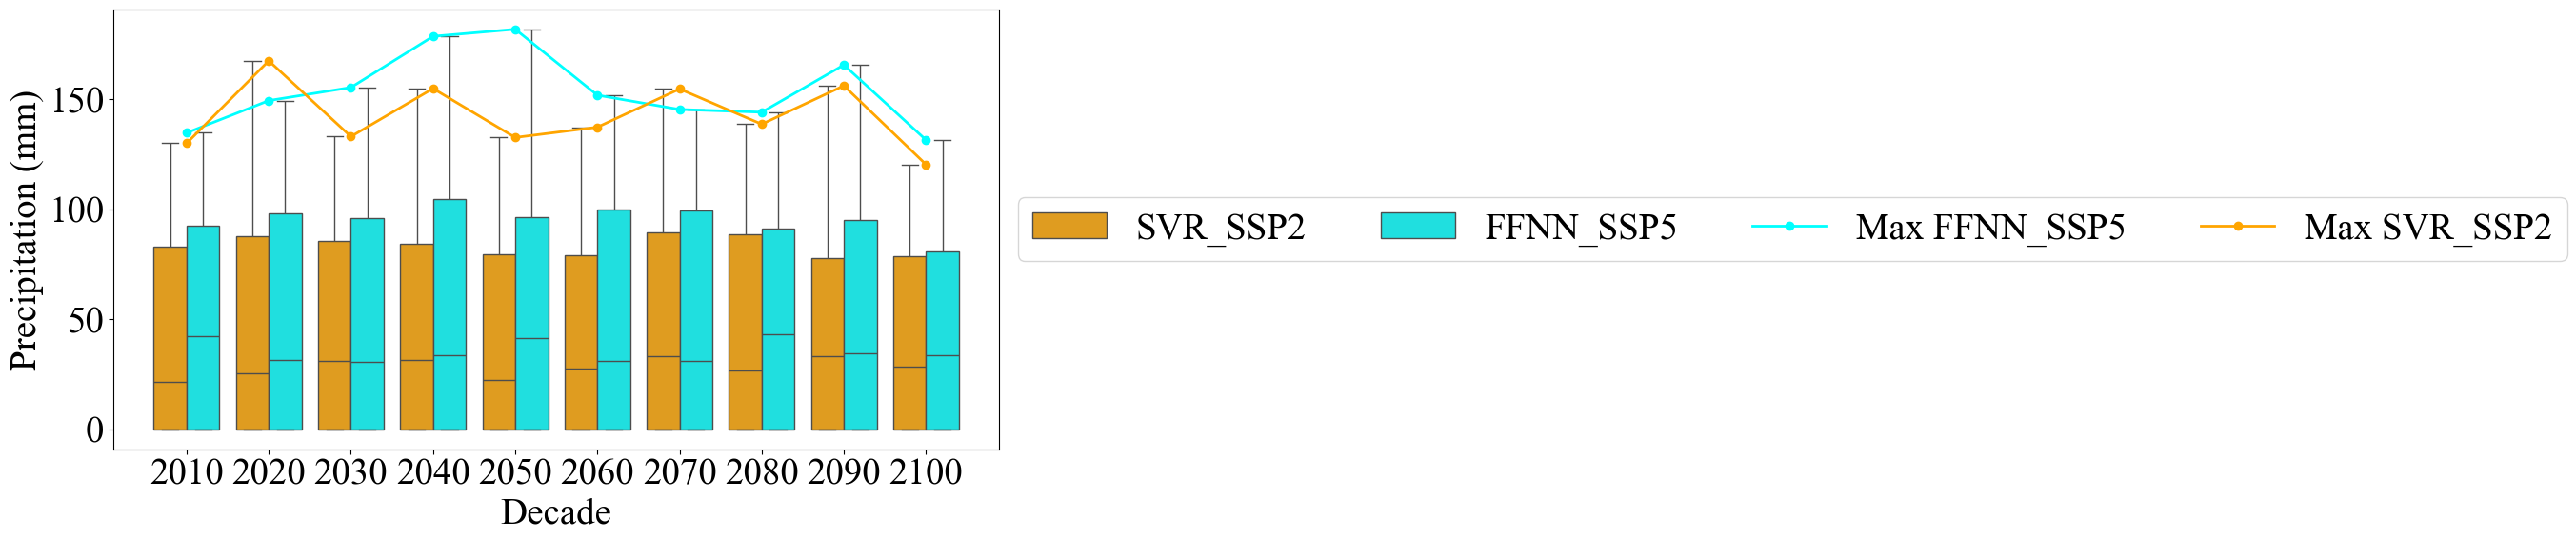

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Assuming 'projections' already has a DateTime index and the 'Ensemble_SSP2' and 'Ensemble_SSP5' columns
projections['decade'] = (projections.index.year // 10) * 10

# Melt your DataFrame so that each row corresponds to one scenario's precipitation value
melted_df = pd.melt(
    projections.reset_index(), 
    id_vars=['index','decade'], 
    value_vars=['SVR_SSP2', 'FFNN_SSP5'],
    var_name='scenario', 
    value_name='precipitation'
)

# Define the order of decades (as numbers)
order = sorted(melted_df['decade'].unique())
# Create a mapping from decade to its position (0, 1, 2, ...)
decade_to_pos = {dec: pos for pos, dec in enumerate(order)}

plt.figure(figsize=(12, 6))

# Create the boxplot with the specified order
ax = sns.boxplot(
    data=melted_df,
    x='decade', 
    y='precipitation',
    hue='scenario',
    palette={'FFNN_SSP5': 'cyan', 'SVR_SSP2': 'orange'},
    showfliers=True,
    whis=100,
    order=order,
    legend=True
)

plt.xlabel('Decade')
plt.ylabel('Precipitation (mm)')
#plt.title('Decadal Precipitation Variability - Ensemble under SSP5 & SSP2')

# Compute the mean precipitation per decade for each scenario
mean_df = melted_df.groupby(['scenario', 'decade'], as_index=False)['precipitation'].max()

# Define colors matching your palette
colors = {'FFNN_SSP5': 'cyan', 'SVR_SSP2': 'orange'}

# Overlay a line connecting the means for each scenario using the mapped positions
for scenario, group in mean_df.groupby('scenario'):
    group = group.sort_values('decade')
    # Map each decade value to its x-axis position from the boxplot
    x_positions = [decade_to_pos[dec] for dec in group['decade']]
    plt.plot(x_positions, group['precipitation'], 
             marker='o', linestyle='-', linewidth=2, 
             color=colors[scenario], 
             label=f'Max {scenario}')

# Since the x-axis is categorical, update the tick positions and labels accordingly
plt.xticks(ticks=range(len(order)), labels=order)
plt.rcParams['font.size']=28
# Combine legends and adjust (avoid duplicate legend entries)
handles, labels = ax.get_legend_handles_labels()
# Remove duplicates by using a dictionary
unique = dict(zip(labels, handles))
plt.legend(unique.values(), unique.keys(),  loc='center left', bbox_to_anchor=(1, 0.5), ncol=4)

plt.show()


In [ ]:
scores=pd.DataFrame(columns=['FFNN_SSP2', 'ANFIS_SSP5', 'SVR_SSP2','FFNN_SSP5', 'ANFIS_SSP5', 'SVR_SSP5','Ensemble_SSP2','Ensemble_SSP5'],index=['R2','CC','RMSE'])
print(f'R2 Score FFNN SSP5: {r2_ffnn_ssp5}')
print(f'R2 Score SVR SSP5: {r2_svr_ssp5}')
print(f'R2 Score ANFIS SSP5: {r2_anfis_ssp5}')
print(f'R2 Score Ensemble SSP5: {r2_ensemble_ssp5}')
cc_ffnn_ssp5 = np.corrcoef(observations_raw['PRCP'] , predictions['FFNN_SSP5'] )[0][1]
cc_svr_ssp5 = np.corrcoef(observations_raw['PRCP'] , predictions['SVR_SSP5'] )[0][1]
cc_anfis_ssp5 = np.corrcoef(observations_raw['PRCP'] , predictions['ANFIS_SSP5'] )[0][1]
cc_ensemble_ssp5 = np.corrcoef(observations_raw['PRCP'] , revalidation_ensemble_ssp5[:observations_raw['PRCP'].shape[0]].flatten() )[0][1]
rmse_ffnn_ssp5 = root_mean_squared_error(observations_raw['PRCP'], predictions['FFNN_SSP5'])
rmse_svr_ssp5 = root_mean_squared_error(observations_raw['PRCP'], predictions['SVR_SSP5'])
rmse_anfis_ssp5 = root_mean_squared_error(observations_raw['PRCP'], predictions['ANFIS_SSP5'])
rmse_ensemble_ssp5 = root_mean_squared_error(observations_raw['PRCP'], revalidation_ensemble_ssp5[:observations_raw['PRCP'].shape[0]].flatten())
print(f'CC Score FFNN SSP5: {cc_ffnn_ssp5}')
print(f'CC Score SVR SSP5: {cc_svr_ssp5}')
print(f'CC Score ANFIS SSP5: {cc_anfis_ssp5}')
print(f'CC Score Ensemble SSP5: {cc_ensemble_ssp5}')
print(f'R2 Score FFNN SSP2: {r2_ffnn_ssp2}')
print(f'R2 Score SVR SSP2: {r2_svr_ssp2}')
print(f'R2 Score ANFIS SSP2: {r2_anfis_ssp2}')
print(f'R2 Score Ensemble SSP2: {r2_ensemble_ssp2}')
print(f'RMSE Score FFNN SSP5: {rmse_ffnn_ssp5}')
print(f'RMSE Score SVR SSP5: {rmse_svr_ssp5}')
print(f'RMSE Score ANFIS SSP5: {rmse_anfis_ssp5}')
print(f'RMSE Score Ensemble SSP5: {rmse_ensemble_ssp5}')
cc_ffnn_ssp2 = np.corrcoef(observations_raw['PRCP'] , predictions['FFNN_SSP2'] )[0][1]
cc_svr_ssp2 = np.corrcoef(observations_raw['PRCP'] , predictions['SVR_SSP2'] )[0][1]
cc_anfis_ssp2 = np.corrcoef(observations_raw['PRCP'] , predictions['ANFIS_SSP2'] )[0][1]
cc_ensemble_ssp2 = np.corrcoef(observations_raw['PRCP'] , revalidation_ensemble_ssp2[:observations_raw['PRCP'].shape[0]].flatten() )[0][1]
rmse_ffnn_ssp2 = root_mean_squared_error(observations_raw['PRCP'], predictions['FFNN_SSP2'])
rmse_svr_ssp2 = root_mean_squared_error(observations_raw['PRCP'], predictions['SVR_SSP2'])
rmse_anfis_ssp2 = root_mean_squared_error(observations_raw['PRCP'], predictions['ANFIS_SSP2'])
rmse_ensemble_ssp2 = root_mean_squared_error(observations_raw['PRCP'], revalidation_ensemble_ssp2[:observations_raw['PRCP'].shape[0]].flatten())
print(f'CC Score FFNN SSP2: {cc_ffnn_ssp2}')
print(f'CC Score SVR SSP2: {cc_svr_ssp2}')
print(f'CC Score ANFIS SSP2: {cc_anfis_ssp2}')
print(f'CC Score Ensemble SSP2: {cc_ensemble_ssp2}')
print(f'RMSE Score FFNN SSP2: {rmse_ffnn_ssp2}')
print(f'RMSE Score SVR SSP2: {rmse_svr_ssp2}')
print(f'RMSE Score ANFIS SSP2: {rmse_anfis_ssp2}')
print(f'RMSE Score Ensemble SSP2: {rmse_ensemble_ssp2}')
scores.loc['R2','FFNN_SSP5']=r2_ffnn_ssp5
scores.loc['R2','SVR_SSP5']=r2_svr_ssp5
scores.loc['R2','ANFIS_SSP5']=r2_anfis_ssp5
scores.loc['R2','Ensemble_SSP5']=r2_ensemble_ssp5
scores.loc['CC','FFNN_SSP5']=cc_ffnn_ssp5
scores.loc['CC','SVR_SSP5']=cc_svr_ssp5
scores.loc['CC','ANFIS_SSP5']=cc_anfis_ssp5
scores.loc['CC','Ensemble_SSP5']=cc_ensemble_ssp5
scores.loc['R2','FFNN_SSP2']=r2_ffnn_ssp2
scores.loc['R2','SVR_SSP2']=r2_svr_ssp2
scores.loc['R2','ANFIS_SSP2']=r2_anfis_ssp2
scores.loc['R2','Ensemble_SSP2']=r2_ensemble_ssp2
scores.loc['CC','FFNN_SSP2']=cc_ffnn_ssp2
scores.loc['CC','SVR_SSP2']=cc_svr_ssp2
scores.loc['CC','ANFIS_SSP2']=cc_anfis_ssp2
scores.loc['CC','Ensemble_SSP2']=cc_ensemble_ssp2
scores.loc['RMSE','FFNN_SSP5']=rmse_ffnn_ssp5
scores.loc['RMSE','SVR_SSP5']=rmse_svr_ssp5
scores.loc['RMSE','ANFIS_SSP5']=rmse_anfis_ssp5
scores.loc['RMSE','Ensemble_SSP5']=rmse_ensemble_ssp5
scores.loc['RMSE','FFNN_SSP2']=rmse_ffnn_ssp2
scores.loc['RMSE','SVR_SSP2']=rmse_svr_ssp2
scores.loc['RMSE','ANFIS_SSP2']=rmse_anfis_ssp2
scores.loc['RMSE','Ensemble_SSP2']=rmse_ensemble_ssp2
scores.to_excel(rf".\Sample Date\{station}\results\{station}_outputs.xlsx")

R2 Score FFNN SSP5: 0.3498878416231762
R2 Score SVR SSP5: 0.34312607126737993
R2 Score ANFIS SSP5: 0.28626190363337667
R2 Score Ensemble SSP5: 0.32876505869178263
CC Score FFNN SSP5: 0.6211187239673207
CC Score SVR SSP5: 0.5986553035276684
CC Score ANFIS SSP5: 0.5449307873533461
CC Score Ensemble SSP5: 0.6150565050879301
R2 Score FFNN SSP2: 0.3095352246715327
R2 Score SVR SSP2: 0.33584070529483023
R2 Score ANFIS SSP2: 0.3338668489221437
R2 Score Ensemble SSP2: 0.266302975982072
RMSE Score FFNN SSP5: 51.49784971170587
RMSE Score SVR SSP5: 51.76496967194636
RMSE Score ANFIS SSP5: 53.959061871958056
RMSE Score Ensemble SSP5: 51.31888097610973
CC Score FFNN SSP2: 0.5827576869003268
CC Score SVR SSP2: 0.5930089783176844
CC Score ANFIS SSP2: 0.580284254913317
CC Score Ensemble SSP2: 0.5748091735109441
RMSE Score FFNN SSP2: 53.072031889843814
RMSE Score SVR SSP2: 52.051239849623556
RMSE Score ANFIS SSP2: 52.12852962741672
RMSE Score Ensemble SSP2: 55.81629481324773
